# Projet 10 : Produisez une étude de marché avec Python

## Partie 3 : Analyse des données - Choix des pays où exporter

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import seaborn as sns

import os
os.environ["OMP_NUM_THREADS"] = '1'

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [2]:
sns.set()

In [3]:
#Importation du fichier poulet_dev.csv
poulet_dev = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 10/poulet_dev.csv")

In [4]:
poulet_dev.head()

,Country,Region,Cluster,Produit,Year,Domestic supply,Exportations,Importations,Production,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,Infrastructures,GES per capita,Renewable energy consumption,Tariffs
0,Australia,AP,3,Viande de Volailles,2017,1171.0,42.0,16.0,1269.0,24.58,77.0,0.78,83.31,2.29,1.95,54118.0,3.97,24.92,9.9,0.00
1,Austria,WE/EU,3,Viande de Volailles,2017,173.0,78.0,110.0,148.0,8.82,75.0,0.93,82.72,2.27,2.08,47164.0,4.18,9.65,34.0,0.00
2,Canada,AME,3,Viande de Volailles,2017,1433.0,163.0,182.0,1417.0,36.73,82.0,1.02,89.27,3.03,1.60,45130.0,3.75,21.51,22.8,1.19
3,Chile,AME,3,Viande de Volailles,2017,672.0,115.0,155.0,712.0,18.47,67.0,0.59,70.05,1.36,2.18,14880.0,3.21,6.71,24.1,0.00
4,Cyprus,WE/EU,3,Viande de Volailles,2017,38.0,1.0,14.0,25.0,1.18,57.0,0.67,73.01,5.75,0.53,26247.0,2.89,7.20,10.9,0.00


In [5]:
poulet_dev.isna().sum()

Country                         0
Region                          0
Cluster                         0
Produit                         0
Year                            0
Domestic supply                 0
Exportations                    0
Importations                    0
Production                      0
Population                      0
CPI Score                       0
Political Stability             0
Government Effectiveness        0
Growth                          0
Inflation                       0
GDP per capita                  0
Infrastructures                 0
GES per capita                  0
Renewable energy consumption    0
Tariffs                         0
dtype: int64

In [6]:
poulet_dev.dtypes

Country                          object
Region                           object
Cluster                           int64
Produit                          object
Year                              int64
Domestic supply                 float64
Exportations                    float64
Importations                    float64
Production                      float64
Population                      float64
CPI Score                       float64
Political Stability             float64
Government Effectiveness        float64
Growth                          float64
Inflation                       float64
GDP per capita                  float64
Infrastructures                 float64
GES per capita                  float64
Renewable energy consumption    float64
Tariffs                         float64
dtype: object

In [7]:
poulet_dev.shape

(42, 20)

In [8]:
countries = poulet_dev['Country']
region = poulet_dev['Region']

In [9]:
poulet_dev.duplicated().sum()

np.int64(0)

In [10]:
cols = [
    "Production",
    "Importations",
    "Exportations",
    "Domestic supply",
    "Population",
    "CPI Score",
    "Political Stability",
    "Government Effectiveness",
    "Growth",
    "Inflation",
    "GDP per capita",
    "GES per capita",
    "Renewable energy consumption",
    "Infrastructures",
    "Tariffs"
]

In [11]:
print([repr(col) for col in poulet_dev.columns])

["'Country'", "'Region'", "'Cluster'", "'Produit'", "'Year'", "'Domestic supply'", "'Exportations'", "'Importations'", "'Production'", "'Population'", "'CPI Score'", "'Political Stability'", "'Government Effectiveness'", "'Growth'", "'Inflation'", "'GDP per capita'", "'Infrastructures'", "'GES per capita'", "'Renewable energy consumption'", "'Tariffs'"]


In [12]:
poulet_end = poulet_dev[cols]
poulet_end.head()

,Production,Importations,Exportations,Domestic supply,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,GES per capita,Renewable energy consumption,Infrastructures,Tariffs
0,1269.0,16.0,42.0,1171.0,24.58,77.0,0.78,83.31,2.29,1.95,54118.0,24.92,9.9,3.97,0.00
1,148.0,110.0,78.0,173.0,8.82,75.0,0.93,82.72,2.27,2.08,47164.0,9.65,34.0,4.18,0.00
2,1417.0,182.0,163.0,1433.0,36.73,82.0,1.02,89.27,3.03,1.60,45130.0,21.51,22.8,3.75,1.19
3,712.0,155.0,115.0,672.0,18.47,67.0,0.59,70.05,1.36,2.18,14880.0,6.71,24.1,3.21,0.00
4,25.0,14.0,1.0,38.0,1.18,57.0,0.67,73.01,5.75,0.53,26247.0,7.20,10.9,2.89,0.00


## 3-2 : Réalisation de l'ACP

In [13]:
X = poulet_end.values
X[:5]

array([[1.2690e+03, 1.6000e+01, 4.2000e+01, 1.1710e+03, 2.4580e+01,
        7.7000e+01, 7.8000e-01, 8.3310e+01, 2.2900e+00, 1.9500e+00,
        5.4118e+04, 2.4920e+01, 9.9000e+00, 3.9700e+00, 0.0000e+00],
       [1.4800e+02, 1.1000e+02, 7.8000e+01, 1.7300e+02, 8.8200e+00,
        7.5000e+01, 9.3000e-01, 8.2720e+01, 2.2700e+00, 2.0800e+00,
        4.7164e+04, 9.6500e+00, 3.4000e+01, 4.1800e+00, 0.0000e+00],
       [1.4170e+03, 1.8200e+02, 1.6300e+02, 1.4330e+03, 3.6730e+01,
        8.2000e+01, 1.0200e+00, 8.9270e+01, 3.0300e+00, 1.6000e+00,
        4.5130e+04, 2.1510e+01, 2.2800e+01, 3.7500e+00, 1.1900e+00],
       [7.1200e+02, 1.5500e+02, 1.1500e+02, 6.7200e+02, 1.8470e+01,
        6.7000e+01, 5.9000e-01, 7.0050e+01, 1.3600e+00, 2.1800e+00,
        1.4880e+04, 6.7100e+00, 2.4100e+01, 3.2100e+00, 0.0000e+00],
       [2.5000e+01, 1.4000e+01, 1.0000e+00, 3.8000e+01, 1.1800e+00,
        5.7000e+01, 6.7000e-01, 7.3010e+01, 5.7500e+00, 5.3000e-01,
        2.6247e+04, 7.2000e+00, 1.0900e+01, 

In [14]:
type(X)

numpy.ndarray

In [15]:
X.shape

(42, 15)

In [16]:
indicators = poulet_end.columns
indicators

Index(['Production', 'Importations', 'Exportations', 'Domestic supply',
       'Population', 'CPI Score', 'Political Stability',
       'Government Effectiveness', 'Growth', 'Inflation', 'GDP per capita',
       'GES per capita', 'Renewable energy consumption', 'Infrastructures',
       'Tariffs'],
      dtype='object')

#### Standardisation des données ####

In [17]:
scaler = StandardScaler()

In [18]:
scaler.fit(X)

,copy,True
,with_mean,True
,with_std,True


In [19]:
X_scaled = scaler.transform(X)
X_scaled[:5]

array([[ 8.01904054e-01, -6.45134291e-01, -3.85229969e-01,
         5.84281103e-01,  9.15274666e-02,  8.35787940e-01,
         2.00880666e-01,  8.40627074e-01, -5.40190044e-01,
        -5.06479332e-02,  8.09278163e-01,  2.47180654e+00,
        -7.69987005e-01,  1.08526448e+00, -4.85436830e-01],
       [-6.06138263e-01, -3.38932057e-01, -2.63603802e-01,
        -5.40798221e-01, -4.22156277e-01,  7.09055733e-01,
         4.77764859e-01,  7.89807410e-01, -5.48619477e-01,
         4.07299911e-02,  5.05933710e-01, -2.12974000e-01,
         6.39914041e-01,  1.49832734e+00, -4.85436830e-01],
       [ 9.87800810e-01, -1.04394176e-01,  2.35690918e-02,
         8.79642609e-01,  4.87546342e-01,  1.15261846e+00,
         6.43895375e-01,  1.35399182e+00, -2.28301012e-01,
        -2.96665421e-01,  4.17207420e-01,  1.87225830e+00,
        -1.53096813e-02,  6.52531962e-01,  3.55684902e+00],
       [ 1.02279103e-01, -1.92345881e-01, -1.38599130e-01,
         2.17414413e-02, -1.07622766e-01,  2.02126904

In [20]:
idx = ["mean", "std"]

pd.DataFrame(X_scaled).describe().round(2).loc[idx, :]

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
mean,0.00,0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,0.00
std,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01,1.01


#### Eboulis des valeurs propres #### 

In [21]:
n_components = 8
pca = PCA(n_components=n_components)

In [22]:
pca.fit(X_scaled)
X_pca = pca.fit_transform(X_scaled)

In [23]:
pca.explained_variance_ratio_

array([0.32980826, 0.22025496, 0.09409243, 0.07953045, 0.07033388,
       0.05519709, 0.04763026, 0.03168414])

In [24]:
scree = (pca.explained_variance_ratio_*100).round(2)
scree

array([32.98, 22.03,  9.41,  7.95,  7.03,  5.52,  4.76,  3.17])

In [25]:
scree_cum = scree.cumsum().round()
scree_cum

array([33., 55., 64., 72., 79., 85., 90., 93.])

In [26]:
x_list = range(1, n_components+1)
list(x_list)

[1, 2, 3, 4, 5, 6, 7, 8]

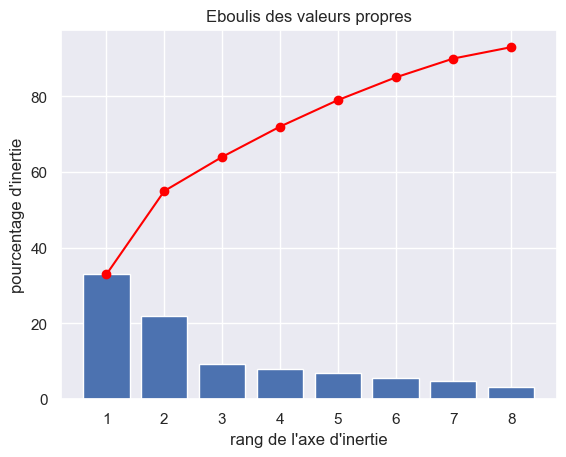

In [27]:
plt.bar(x_list, scree)
plt.plot(x_list, scree_cum,c="red",marker='o')
plt.xlabel("rang de l'axe d'inertie")
plt.ylabel("pourcentage d'inertie")
plt.title("Eboulis des valeurs propres")
plt.show(block=False)

In [28]:
pcs = pca.components_
pcs

array([[ 0.34175825,  0.29393243,  0.10312202,  0.36259095,  0.32245814,
        -0.33011438, -0.35679266, -0.32816229, -0.03601734,  0.18987846,
        -0.30057962, -0.08879953, -0.21991474, -0.14704739,  0.03438677],
       [ 0.27637512,  0.26233315,  0.09301582,  0.28019987,  0.32594229,
         0.3120931 ,  0.02115622,  0.31439144, -0.28749665, -0.15329061,
         0.29684856,  0.22175922, -0.06798806,  0.44744801,  0.12815421],
       [ 0.01197781, -0.108735  , -0.4036206 ,  0.12171934,  0.03684914,
         0.04148946, -0.00463701, -0.00143006, -0.34345125,  0.47838271,
         0.04502149,  0.03540363,  0.45957678, -0.15938675,  0.46957553],
       [ 0.07499147,  0.15097425,  0.50972418, -0.0644252 ,  0.06959057,
         0.15672909,  0.21390315, -0.02079003, -0.13236086,  0.31650632,
        -0.09048946, -0.40692085,  0.46817168,  0.09616365, -0.33484225],
       [-0.17694685,  0.03701916, -0.03671511, -0.11287754, -0.14539703,
         0.02339173, -0.10872513, -0.17717017, 

In [29]:
pcs = pd.DataFrame(pcs)
pcs

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,0.341758,0.293932,0.103122,0.362591,0.322458,-0.330114,-0.356793,-0.328162,-0.036017,0.189878,-0.300580,-0.088800,-0.219915,-0.147047,0.034387
1,0.276375,0.262333,0.093016,0.280200,0.325942,0.312093,0.021156,0.314391,-0.287497,-0.153291,0.296849,0.221759,-0.067988,0.447448,0.128154
2,0.011978,-0.108735,-0.403621,0.121719,0.036849,0.041489,-0.004637,-0.001430,-0.343451,0.478383,0.045021,0.035404,0.459577,-0.159387,0.469576
3,0.074991,0.150974,0.509724,-0.064425,0.069591,0.156729,0.213903,-0.020790,-0.132361,0.316506,-0.090489,-0.406921,0.468172,0.096164,-0.334842
4,-0.176947,0.037019,-0.036715,-0.112878,-0.145397,0.023392,-0.108725,-0.177170,-0.537394,0.202409,-0.144937,0.539099,-0.108260,0.059566,-0.481319
5,-0.049208,0.150414,0.645277,-0.137721,-0.251322,0.025246,-0.125138,-0.110811,0.026212,-0.010201,0.105179,0.384877,0.077786,-0.228985,0.478955
6,0.256465,-0.128234,0.025719,0.147673,0.108959,0.161530,0.411090,0.141744,0.459953,0.449910,-0.061335,0.416681,-0.144814,-0.189912,-0.140940
7,-0.268450,0.662682,-0.245679,0.039819,0.192136,-0.026218,0.159242,-0.110909,0.204676,-0.221338,0.113672,0.188574,0.345075,-0.265502,-0.150493


In [30]:
pcs.columns = indicators
pcs.index = [f"F{i}" for i in x_list]
pcs.round(2)

,Production,Importations,Exportations,Domestic supply,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,GES per capita,Renewable energy consumption,Infrastructures,Tariffs
F1,0.34,0.29,0.10,0.36,0.32,-0.33,-0.36,-0.33,-0.04,0.19,-0.30,-0.09,-0.22,-0.15,0.03
F2,0.28,0.26,0.09,0.28,0.33,0.31,0.02,0.31,-0.29,-0.15,0.30,0.22,-0.07,0.45,0.13
F3,0.01,-0.11,-0.40,0.12,0.04,0.04,-0.00,-0.00,-0.34,0.48,0.05,0.04,0.46,-0.16,0.47
F4,0.07,0.15,0.51,-0.06,0.07,0.16,0.21,-0.02,-0.13,0.32,-0.09,-0.41,0.47,0.10,-0.33
F5,-0.18,0.04,-0.04,-0.11,-0.15,0.02,-0.11,-0.18,-0.54,0.20,-0.14,0.54,-0.11,0.06,-0.48
F6,-0.05,0.15,0.65,-0.14,-0.25,0.03,-0.13,-0.11,0.03,-0.01,0.11,0.38,0.08,-0.23,0.48
F7,0.26,-0.13,0.03,0.15,0.11,0.16,0.41,0.14,0.46,0.45,-0.06,0.42,-0.14,-0.19,-0.14
F8,-0.27,0.66,-0.25,0.04,0.19,-0.03,0.16,-0.11,0.20,-0.22,0.11,0.19,0.35,-0.27,-0.15


In [31]:
pcs.T

,F1,F2,F3,F4,F5,F6,F7,F8
Production,0.341758,0.276375,0.011978,0.074991,-0.176947,-0.049208,0.256465,-0.268450
Importations,0.293932,0.262333,-0.108735,0.150974,0.037019,0.150414,-0.128234,0.662682
Exportations,0.103122,0.093016,-0.403621,0.509724,-0.036715,0.645277,0.025719,-0.245679
Domestic supply,0.362591,0.280200,0.121719,-0.064425,-0.112878,-0.137721,0.147673,0.039819
Population,0.322458,0.325942,0.036849,0.069591,-0.145397,-0.251322,0.108959,0.192136
CPI Score,-0.330114,0.312093,0.041489,0.156729,0.023392,0.025246,0.161530,-0.026218
Political Stability,-0.356793,0.021156,-0.004637,0.213903,-0.108725,-0.125138,0.411090,0.159242
Government Effectiveness,-0.328162,0.314391,-0.001430,-0.020790,-0.177170,-0.110811,0.141744,-0.110909
Growth,-0.036017,-0.287497,-0.343451,-0.132361,-0.537394,0.026212,0.459953,0.204676
Inflation,0.189878,-0.153291,0.478383,0.316506,0.202409,-0.010201,0.449910,-0.221338


<Axes: >

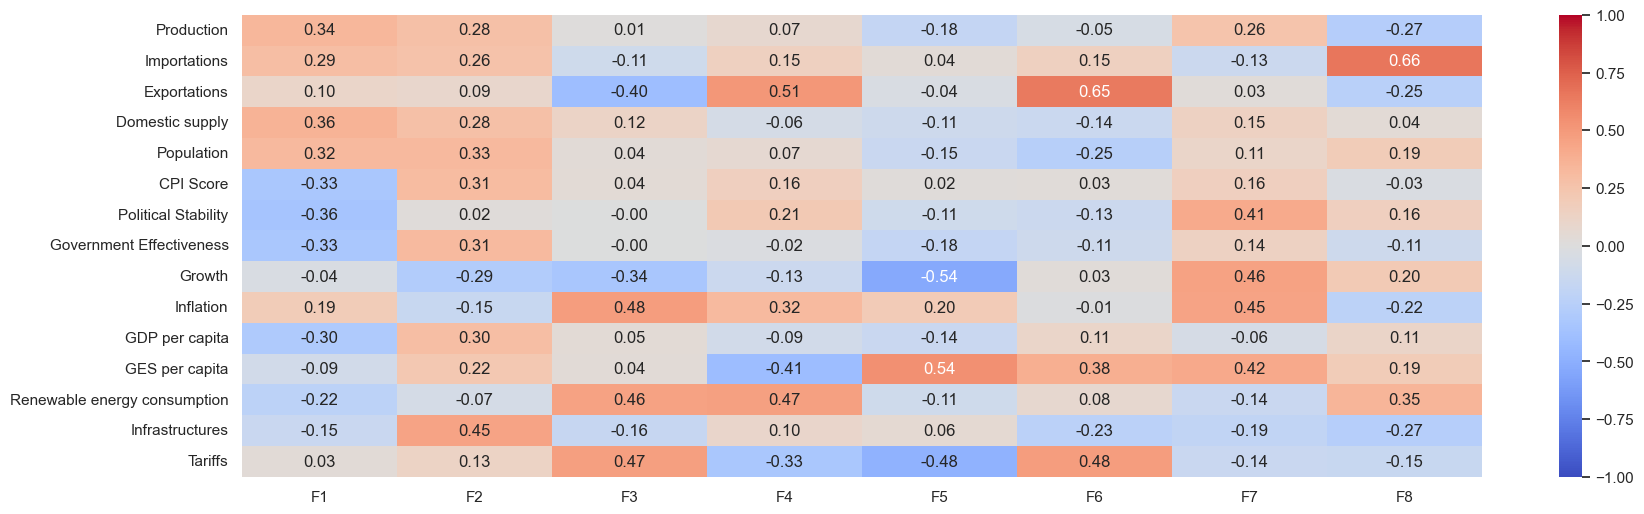

In [32]:
fig, ax = plt.subplots(figsize=(20, 6))
sns.heatmap(pcs.T, vmin=-1, vmax=1, annot=True, cmap="coolwarm", fmt="0.2f")

### Cercle des corrélations ###

In [33]:
x, y = 0,1

In [34]:
def correlation_graph(pca, 
                      x_y, 
                      features) : 
    """Affiche le graphe des correlations

    Positional arguments : 
    -----------------------------------
    pca : sklearn.decomposition.PCA : notre objet PCA qui a été fit
    x_y : list ou tuple : le couple x,y des plans à afficher, exemple [0,1] pour F1, F2
    features : list ou tuple : la liste des features (ie des dimensions) à représenter
    """

    # Extrait x et y 
    x,y=x_y

    # Taille de l'image (en inches)
    fig, ax = plt.subplots(figsize=(10, 9))

    # Pour chaque composante : 
    for i in range(0, pca.components_.shape[1]):

        # Les flèches
        ax.arrow(0,0, 
                pca.components_[x, i],  
                pca.components_[y, i],  
                head_width=0.07,
                head_length=0.07, 
                width=0.02, )

        # Les labels
        plt.text(pca.components_[x, i] + 0.05,
                pca.components_[y, i] + 0.05,
                features[i])
        
    # Affichage des lignes horizontales et verticales
    plt.plot([-1, 1], [0, 0], color='grey', ls='--')
    plt.plot([0, 0], [-1, 1], color='grey', ls='--')

    # Nom des axes, avec le pourcentage d'inertie expliqué
    plt.xlabel('F{} ({}%)'.format(x+1, round(100*pca.explained_variance_ratio_[x],1)))
    plt.ylabel('F{} ({}%)'.format(y+1, round(100*pca.explained_variance_ratio_[y],1)))

    plt.title("Cercle des corrélations (F{} et F{})".format(x+1, y+1))

    # Le cercle 
    an = np.linspace(0, 2 * np.pi, 100)
    plt.plot(np.cos(an), np.sin(an))  # Add a unit circle for scale

    # Axes et display
    plt.axis('equal')
    plt.show(block=False)

In [35]:
x_y = (0,1)
x_y

(0, 1)

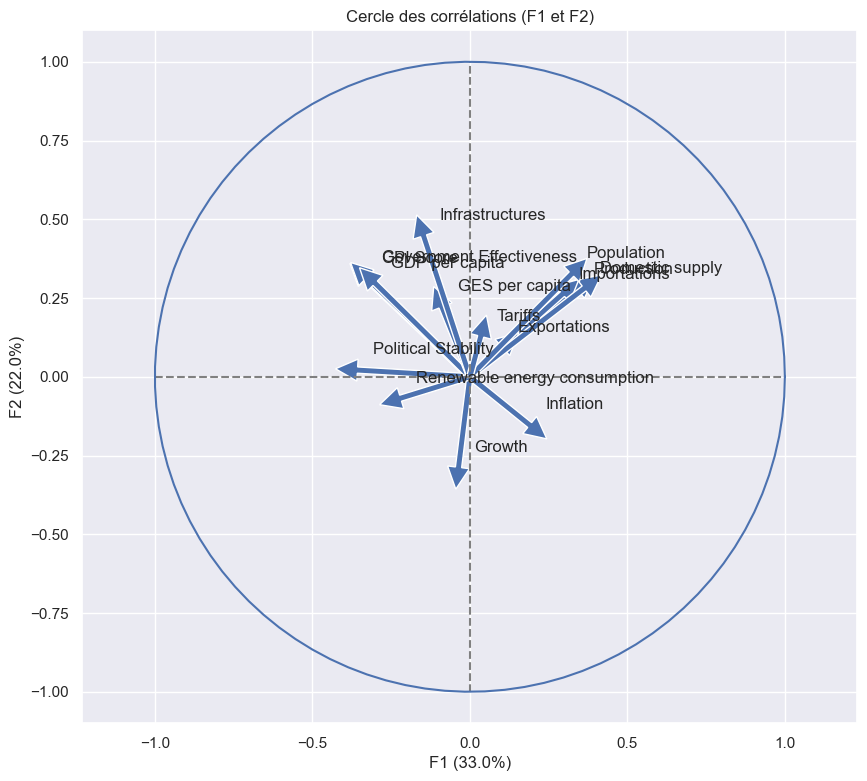

In [36]:
correlation_graph(pca, x_y, indicators)

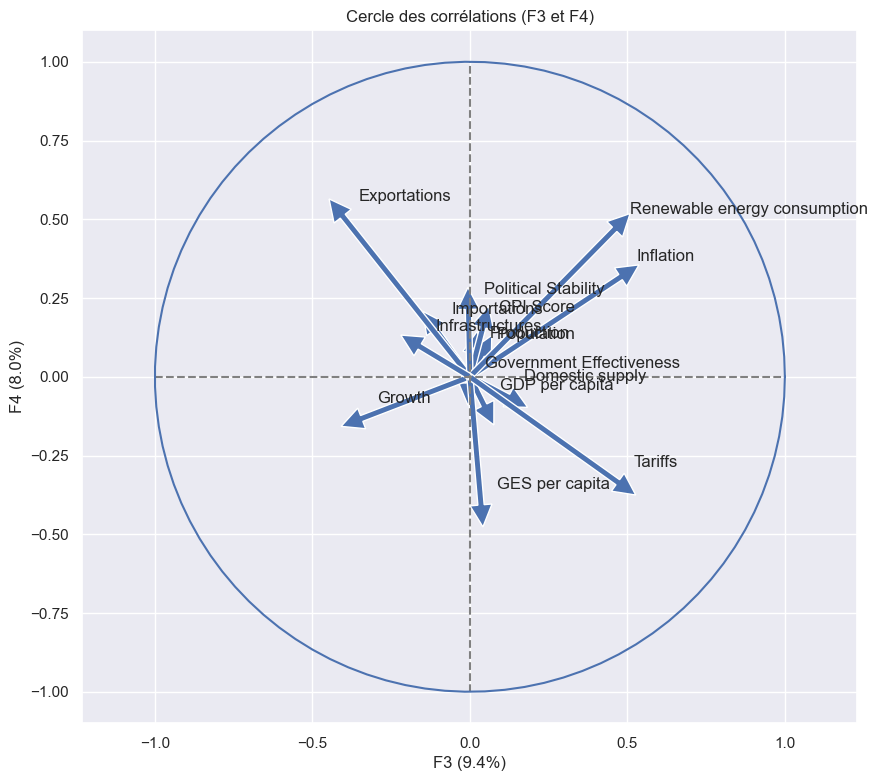

In [37]:
correlation_graph(pca, (2,3), indicators)

### Projection des individus ###

In [38]:
X_proj = pca.transform(X_scaled)
X_proj[:5]

array([[-0.79722086,  2.16666559, -0.12727424, -1.22558159,  1.49483262,
        -0.10382355,  1.39436148, -0.61248549],
       [-1.81330508,  0.72876943,  0.13115452,  0.70398539,  0.42006953,
        -0.7094517 , -0.48433006, -0.33776818],
       [-0.57910866,  2.85121757,  1.76233173, -1.66087565, -1.29258087,
         1.82018058,  0.9862115 , -0.58368937],
       [ 0.44386858, -0.52732753,  0.25832624,  0.59376032,  0.53088911,
        -0.57744877, -0.5230413 , -0.38920032],
       [-0.57498616, -1.83755937, -1.10121798, -0.91678595, -0.44110262,
        -0.44555946, -0.30173794,  0.11647083]])

In [39]:
def display_factorial_planes(   X_projected, 
                                x_y, 
                                pca=None, 
                                labels= None,
                                clusters=None, 
                                alpha=1,
                                figsize=[20,16], 
                                s=100,
                                marker="o" ):
    """
    Affiche la projection des individus

    Positional arguments : 
    -------------------------------------
    X_projected : np.array, pd.DataFrame, list of list : la matrice des points projetés
    x_y : list ou tuple : le couple x,y des plans à afficher, exemple [0,1] pour F1, F2

    Optional arguments : 
    -------------------------------------
    pca : sklearn.decomposition.PCA : un objet PCA qui a été fit, cela nous permettra d'afficher la variance de chaque composante, default = None
    labels : list ou tuple : les labels des individus à projeter, default = None
    clusters : list ou tuple : la liste des clusters auquel appartient chaque individu, default = None
    alpha : float in [0,1] : paramètre de transparence, 0=100% transparent, 1=0% transparent, default = 1
    figsize : list ou tuple : couple width, height qui définit la taille de la figure en inches, default = [10,8] 
    marker : str : le type de marker utilisé pour représenter les individus, points croix etc etc, default = "."
    """

    # Transforme X_projected en np.array
    X_ = np.array(X_projected)

    # On définit la forme de la figure si elle n'a pas été donnée
    if not figsize: 
        figsize = (7,6)

    # On gère les labels
    if  labels is None : 
        labels = []
    try : 
        len(labels)
    except Exception as e : 
        raise e

    # On vérifie la variable axis 
    if not len(x_y) ==2 : 
        raise AttributeError("2 axes sont demandées")   
    if max(x_y )>= X_.shape[1] : 
        raise AttributeError("la variable axis n'est pas bonne")   

    # on définit x et y 
    x, y = x_y

    # Initialisation de la figure       
    fig, ax = plt.subplots(1, 1, figsize=figsize)

    # On vérifie s'il y a des clusters ou non
    c = None if clusters is None else clusters
 
    # Les points    
    # plt.scatter(   X_[:, x], X_[:, y], alpha=alpha, 
    #                     c=c, cmap="Set1", marker=marker)
    sns.scatterplot(data=None, x=X_[:, x], y=X_[:, y], hue=c)

    # Si la variable pca a été fournie, on peut calculer le % de variance de chaque axe 
    if pca : 
        v1 = str(round(100*pca.explained_variance_ratio_[x]))  + " %"
        v2 = str(round(100*pca.explained_variance_ratio_[y]))  + " %"
    else : 
        v1=v2= ''

    # Nom des axes, avec le pourcentage d'inertie expliqué
    ax.set_xlabel(f'F{x+1} {v1}')
    ax.set_ylabel(f'F{y+1} {v2}')

    # Valeur x max et y max
    x_max = np.abs(X_[:, x]).max() *1.1
    y_max = np.abs(X_[:, y]).max() *1.1

    # On borne x et y 
    ax.set_xlim(left=-x_max, right=x_max)
    ax.set_ylim(bottom= -y_max, top=y_max)

    # Affichage des lignes horizontales et verticales
    plt.plot([-x_max, x_max], [0, 0], color='grey', alpha=0.8)
    plt.plot([0,0], [-y_max, y_max], color='grey', alpha=0.8)

    # Affichage des labels des points
    if len(labels) : 
        for i,(_x,_y) in enumerate(X_[:,[x,y]]):
            plt.text(_x, _y+0.05, labels[i], fontsize='14', ha='center',va='center') 

    # Titre et display
    plt.title(f"Projection des individus (sur F{x+1} et F{y+1})")
    plt.show()

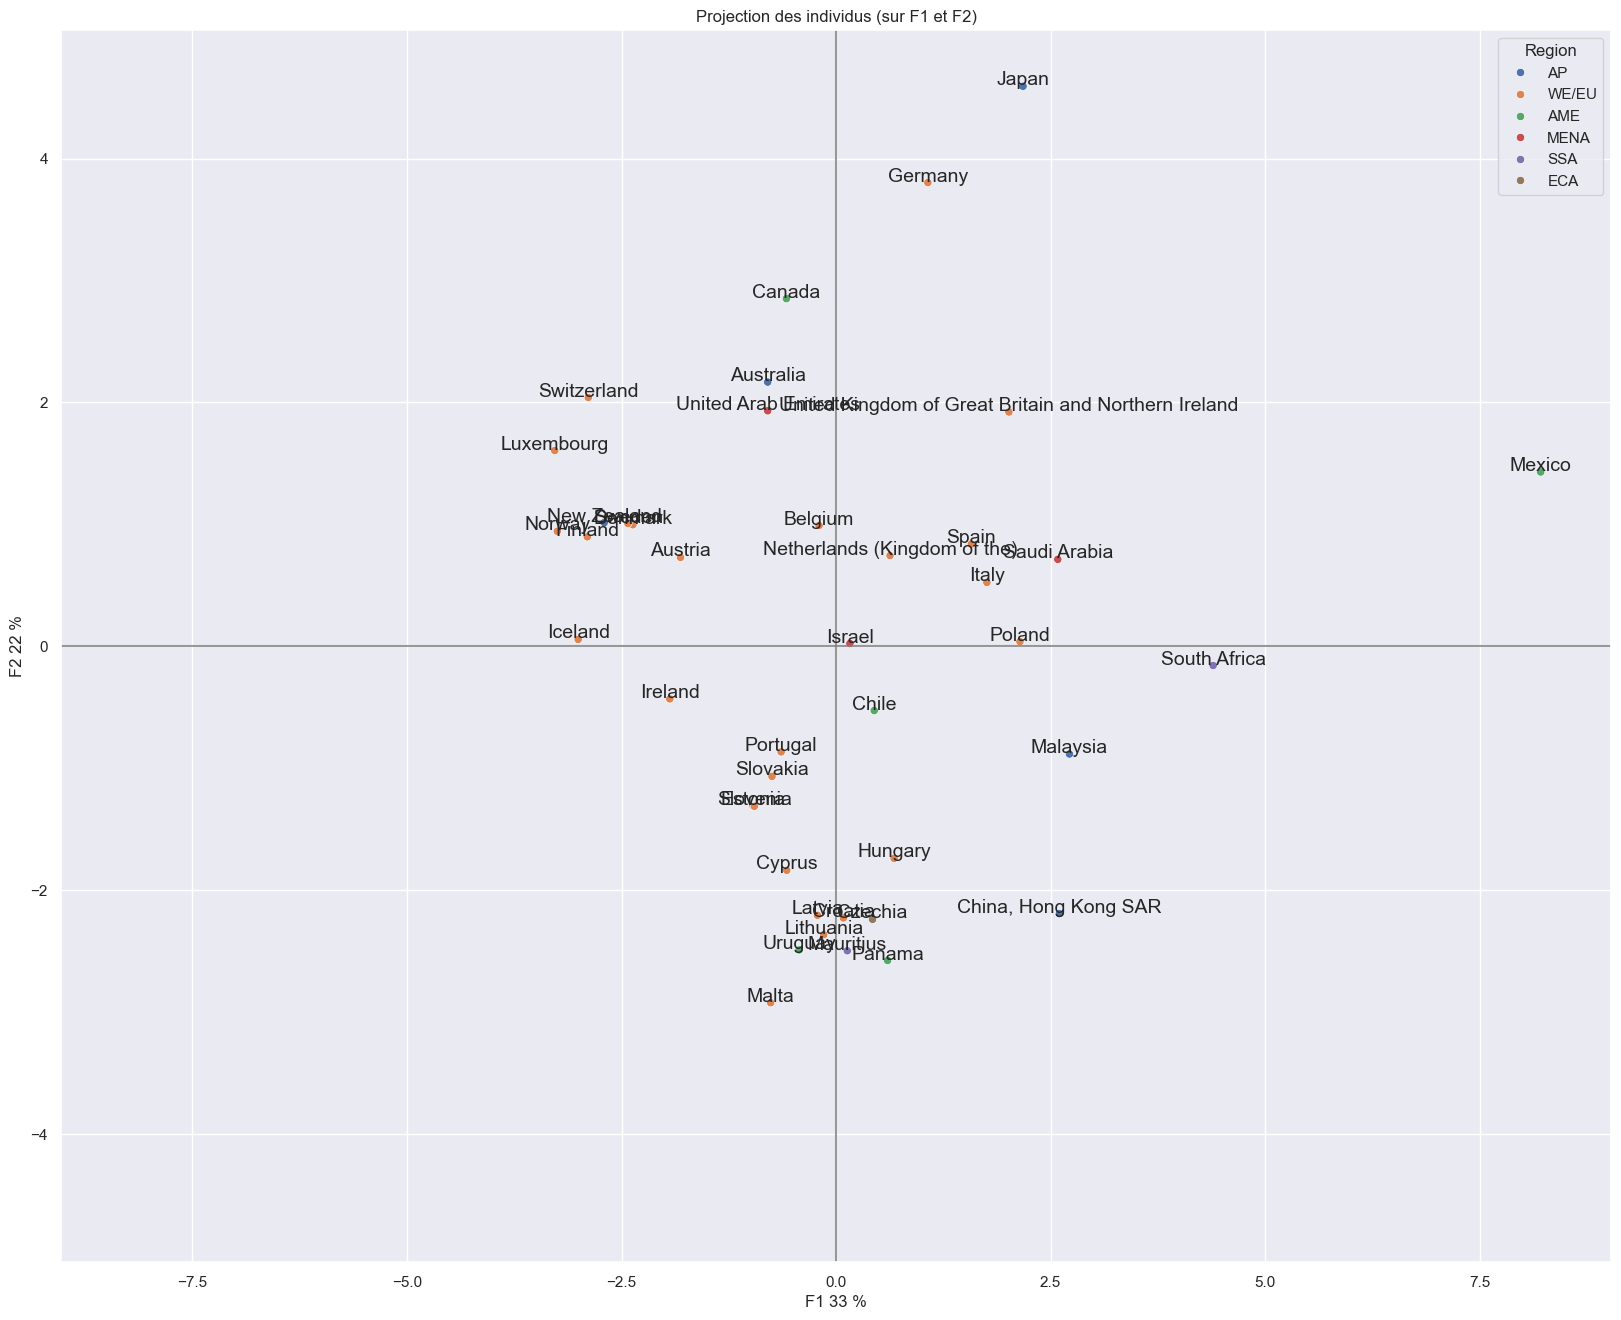

In [41]:
x_y = [0,1]
display_factorial_planes(X_proj, x_y, pca, labels=countries, figsize=(20,16), clusters=region, marker="o")

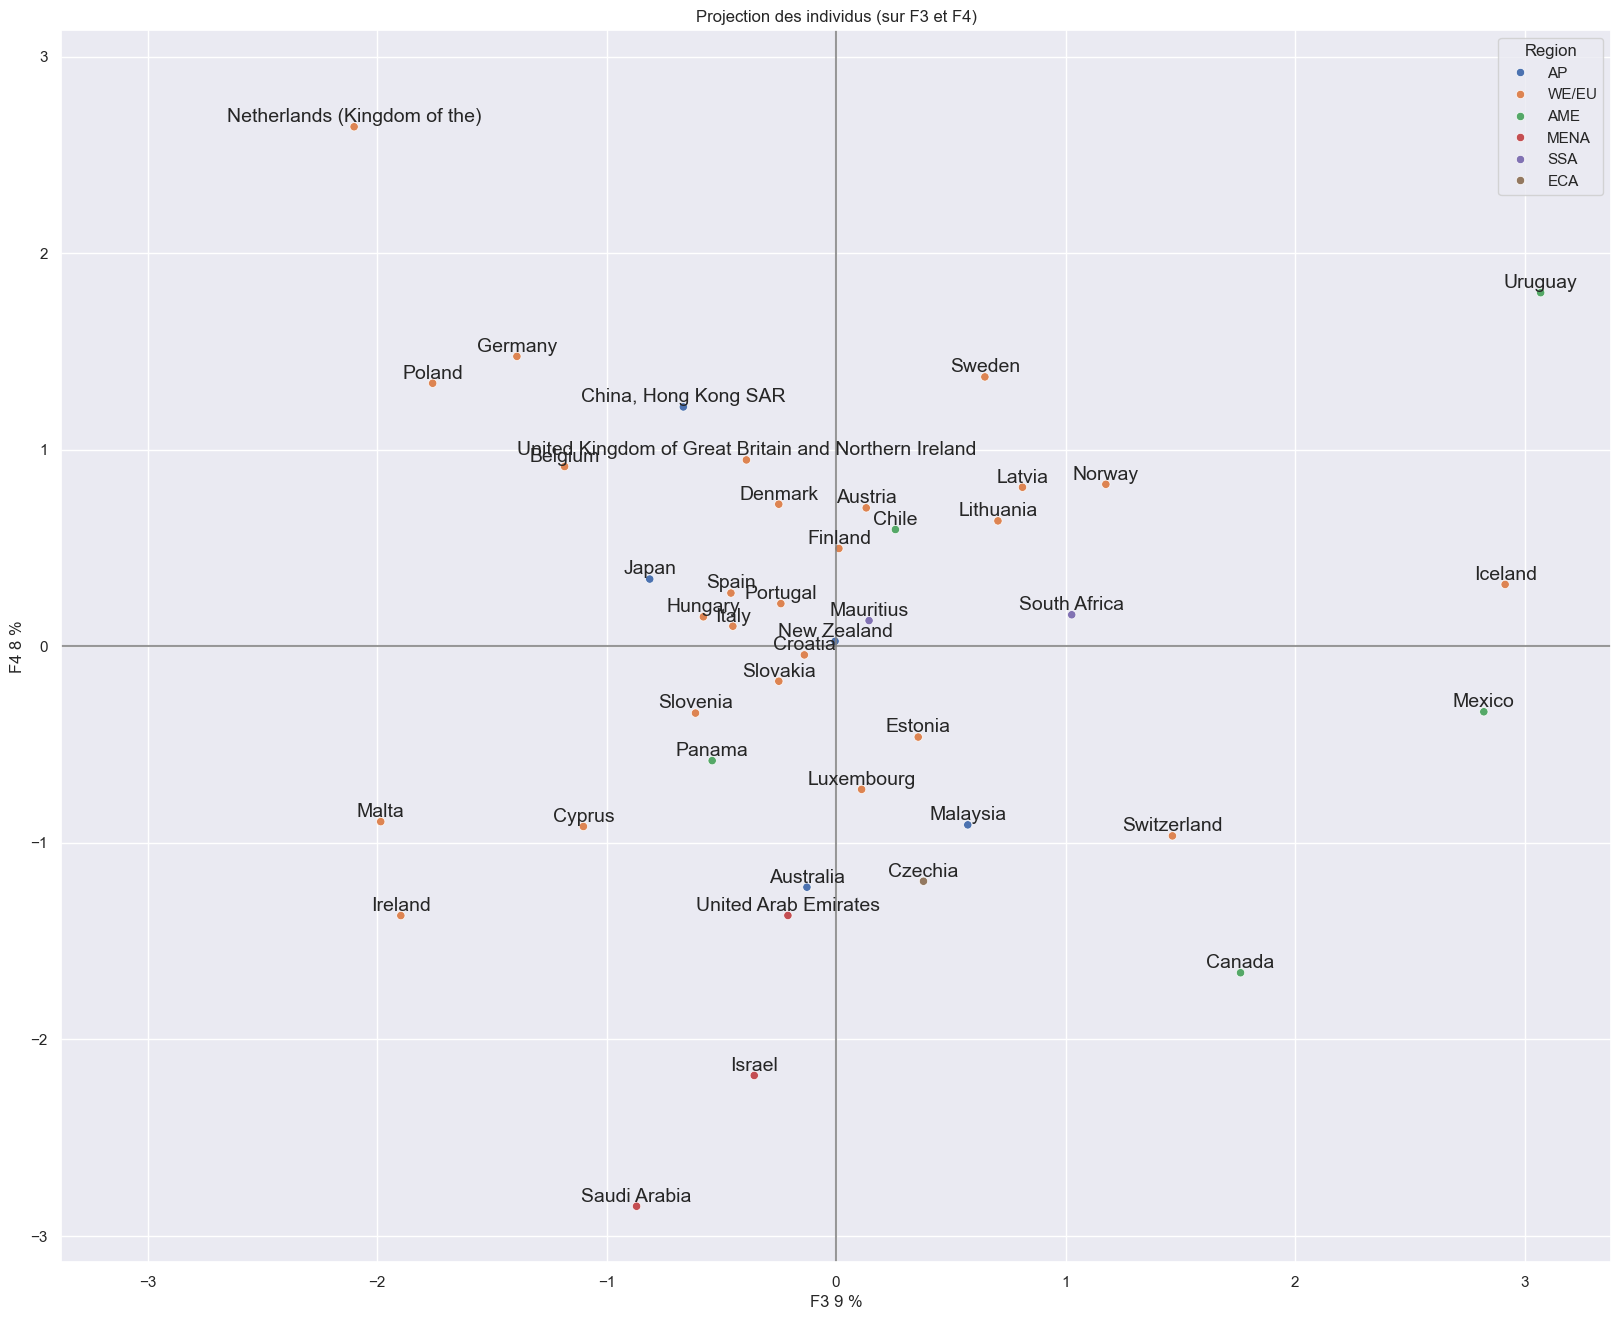

In [47]:
x_y = [2,3]
display_factorial_planes(X_proj, x_y, pca, labels=countries, figsize=(20,16), clusters=region, marker="o")

### Classification Ascendante Hiérarchique ###

#### Dendrogramme ####

In [42]:
Z = linkage(X_scaled, method="ward")
Z[:10]

array([[29.        , 31.        ,  1.14433347,  2.        ],
       [17.        , 18.        ,  1.22730583,  2.        ],
       [ 5.        ,  7.        ,  1.29896369,  2.        ],
       [32.        , 42.        ,  1.48551907,  3.        ],
       [ 1.        , 35.        ,  1.51436795,  2.        ],
       [15.        , 34.        ,  1.57204606,  2.        ],
       [11.        , 26.        ,  1.59116087,  2.        ],
       [44.        , 46.        ,  1.72540297,  4.        ],
       [10.        , 48.        ,  1.92731107,  3.        ],
       [ 4.        , 45.        ,  1.97203056,  4.        ]])

In [43]:
countries = countries.tolist()

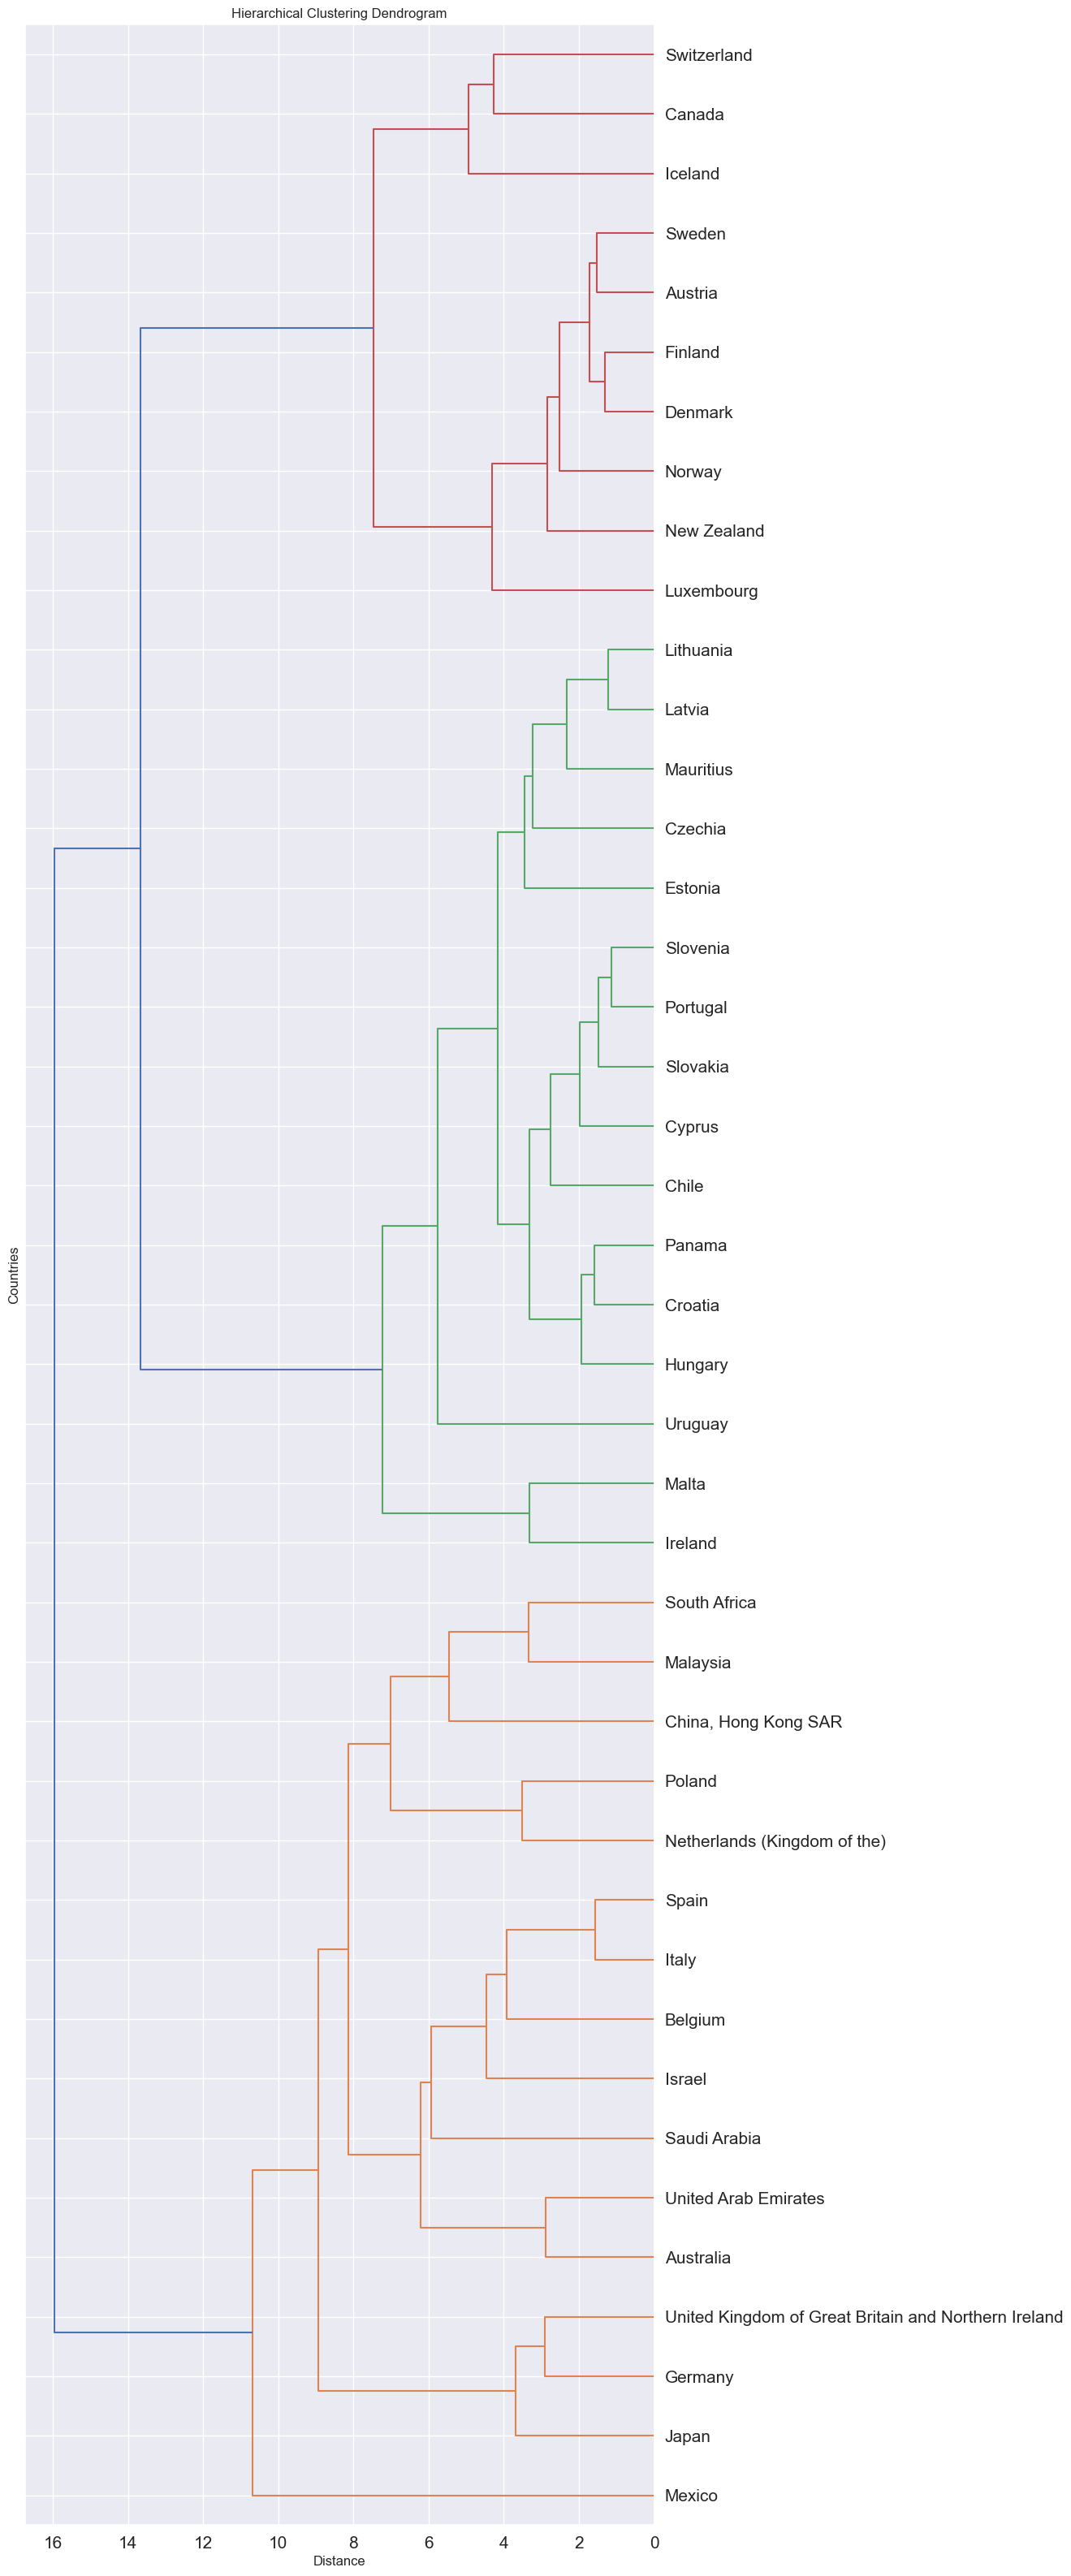

In [44]:
fig, ax = plt.subplots(1, 1, figsize=(10,40))

_ = dendrogram(Z, ax=ax, labels=countries, orientation = "left")

plt.title("Hierarchical Clustering Dendrogram")
ax.set_xlabel("Distance")
ax.set_ylabel("Countries")
ax.tick_params(axis='x', which='major', labelsize=15)
ax.tick_params(axis='y', which='major', labelsize=15)

On distingue 3 groupes de pays : 
- les pays en rouge,
- les pays en vert,
- les pays en orange

On va donc utiliser ce nombre de clusters pour notre k-means.

#### K-means ####

In [45]:
k=3

In [48]:
clusters = fcluster(Z, k, criterion='maxclust')
clusters

array([1, 3, 3, 2, 2, 3, 2, 3, 1, 1, 2, 2, 3, 2, 1, 1, 1, 2, 2, 1, 2, 2,
       1, 1, 3, 3, 2, 2, 1, 2, 1, 2, 2, 1, 1, 3, 3, 1, 1, 2, 1, 3],
      dtype=int32)

In [49]:
crosstab = pd.crosstab(region, clusters, dropna=False)
crosstab.rename_axis(columns="cluster", inplace=True)
crosstab

cluster,1,2,3
Region,,,
AME,1,3,1
AP,4,0,1
ECA,0,1,0
MENA,3,0,0
SSA,1,1,0
WE/EU,7,11,8


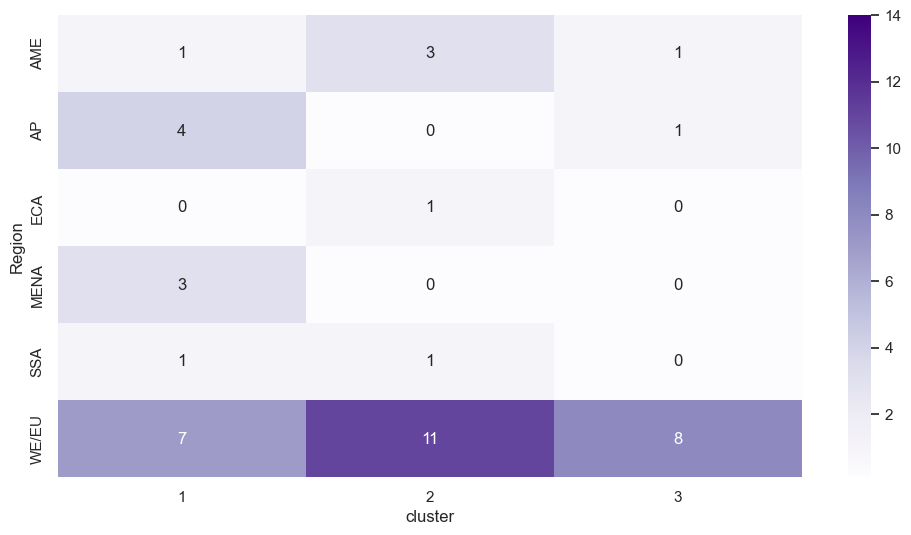

In [50]:
fig, ax = plt.subplots(1,1, figsize=(12,6))
ax = sns.heatmap(crosstab, vmin=0.1, vmax=14, annot=True, cmap="Purples")

In [51]:
df = pd.DataFrame({"Country" : countries, "Region" : region, "Cluster" : clusters})
df.head(50)

,Country,Region,Cluster
0,Australia,AP,1
1,Austria,WE/EU,3
2,Canada,AME,3
3,Chile,AME,2
4,Cyprus,WE/EU,2
5,Denmark,WE/EU,3
6,Estonia,WE/EU,2
7,Finland,WE/EU,3
8,Germany,WE/EU,1
9,"China, Hong Kong SAR",AP,1


In [52]:
intertia_list = [ ]

# Notre liste de nombres de clusters : 
k_list = range(1, 4)

# Pour chaque nombre de clusters : 
for k in k_list : 
    
    # On instancie un k-means pour k clusters
    kmeans = KMeans(n_clusters=k)
    
    # On entraine
    kmeans.fit(X)
    
    # On enregistre l'inertie obtenue : 
    intertia_list.append(kmeans.inertia_)

In [53]:
kmeans.labels_

array([0, 0, 0, 2, 2, 0, 2, 0, 0, 2, 2, 2, 1, 1, 0, 0, 0, 2, 2, 2, 0, 2,
       2, 0, 0, 1, 2, 2, 2, 2, 2, 2, 0, 2, 2, 0, 1, 0, 0, 2, 0, 1],
      dtype=int32)

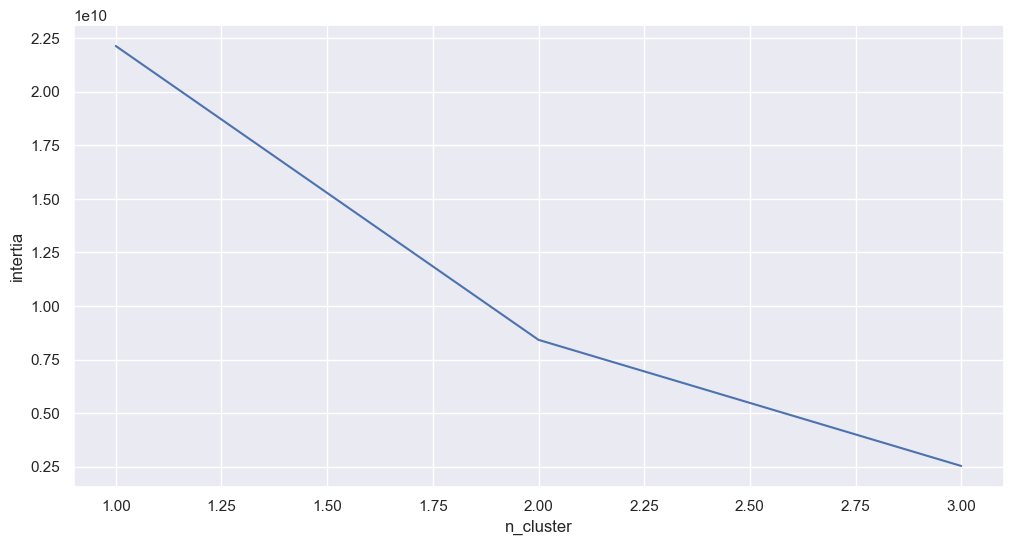

In [54]:
fig, ax = plt.subplots(1,1,figsize=(12,6))

ax.set_ylabel("intertia")
ax.set_xlabel("n_cluster")

ax = plt.plot(k_list, intertia_list)

**Le coude se situe autour de 2 clusters.**

Mais l'on va utiliser 3 clusters aux vues du dendrogramme.


In [55]:
poulet_end.loc[:, "Cluster"] = clusters
poulet_end.groupby("Cluster")[indicators].mean()

C:\Users\capel\AppData\Local\Temp\ipykernel_22948\559197371.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  poulet_end.loc[:, "Cluster"] = clusters


,Production,Importations,Exportations,Domestic supply,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,GES per capita,Renewable energy consumption,Infrastructures,Tariffs
Cluster,,,,,,,,,,,,,,,
1,1344.5625,476.5625,339.8125,1414.3750,46.638125,59.107474,0.228563,69.280898,2.746034,2.132846,30056.126068,12.063859,12.033583,3.549373,0.138990
2,157.6250,48.3125,42.0625,143.0625,5.133750,56.394231,0.837019,68.931899,5.019615,2.230048,23455.670673,8.815216,23.728365,3.007921,0.037539
3,244.9000,59.2000,44.3000,249.5000,8.607000,83.200000,1.114000,87.772000,2.576000,1.512000,63757.300000,12.211000,39.640000,3.865000,0.317762


**Cluster 1** : pays producteurs de poulet, importent plus que ce qu'ils n'exportent, population elevée, PIB / hab moyen

**Cluster 2** : droits de douane très faibles, importent/exportent à peu près pareil, faible population

**Cluster 3** : petits pays très riches, importent plus que ce qu'ils n'exportent, mais droits de douane élevés

In [56]:
poulet_end.shape

(42, 16)

In [57]:
poulet_end.head()

,Production,Importations,Exportations,Domestic supply,Population,CPI Score,Political Stability,Government Effectiveness,Growth,Inflation,GDP per capita,GES per capita,Renewable energy consumption,Infrastructures,Tariffs,Cluster
0,1269.0,16.0,42.0,1171.0,24.58,77.0,0.78,83.31,2.29,1.95,54118.0,24.92,9.9,3.97,0.00,1
1,148.0,110.0,78.0,173.0,8.82,75.0,0.93,82.72,2.27,2.08,47164.0,9.65,34.0,4.18,0.00,3
2,1417.0,182.0,163.0,1433.0,36.73,82.0,1.02,89.27,3.03,1.60,45130.0,21.51,22.8,3.75,1.19,3
3,712.0,155.0,115.0,672.0,18.47,67.0,0.59,70.05,1.36,2.18,14880.0,6.71,24.1,3.21,0.00,2
4,25.0,14.0,1.0,38.0,1.18,57.0,0.67,73.01,5.75,0.53,26247.0,7.20,10.9,2.89,0.00,2


#### Résultat final : Détermination des pays ####

In [58]:
print(df[df["Cluster"] == 3])

        Country Region  Cluster
1       Austria  WE/EU        3
2        Canada    AME        3
5       Denmark  WE/EU        3
7       Finland  WE/EU        3
12      Iceland  WE/EU        3
24  New Zealand     AP        3
25       Norway  WE/EU        3
35       Sweden  WE/EU        3
36  Switzerland  WE/EU        3
41   Luxembourg  WE/EU        3


In [59]:
print(df[df["Cluster"] == 2])

      Country Region  Cluster
3       Chile    AME        2
4      Cyprus  WE/EU        2
6     Estonia  WE/EU        2
10    Hungary  WE/EU        2
11    Croatia  WE/EU        2
13    Ireland  WE/EU        2
17     Latvia  WE/EU        2
18  Lithuania  WE/EU        2
20      Malta  WE/EU        2
21  Mauritius    SSA        2
26     Panama    AME        2
27    Czechia    ECA        2
29   Portugal  WE/EU        2
31   Slovenia  WE/EU        2
32   Slovakia  WE/EU        2
39    Uruguay    AME        2


In [60]:
print(df[df["Cluster"] == 1])

                                              Country Region  Cluster
0                                           Australia     AP        1
8                                             Germany  WE/EU        1
9                                China, Hong Kong SAR     AP        1
14                                             Israel   MENA        1
15                                              Italy  WE/EU        1
16                                              Japan     AP        1
19                                           Malaysia     AP        1
22                                             Mexico    AME        1
23                       Netherlands (Kingdom of the)  WE/EU        1
28                                             Poland  WE/EU        1
30                                       Saudi Arabia   MENA        1
33                                       South Africa    SSA        1
34                                              Spain  WE/EU        1
37                  

**Recommandation :**

Cibler les pays du cluster 1 en priorité car :
- droits de douane faibles ou nuls lorsque ces pays font partie de l'Union européenne.
- populations suffisamment grandes pour que l'on puisse exporter beaucoup de poulet.
- ces pays importent beaucoup de poulets, il y a une forte demande.

C'est un bon compromis entre les petits pays riches du cluster 3 mais avec des frais de douane élevés, et entre les pays du cluster 2 qui sont des petits pays mais qui ont par contre des droits de douane quasiment nuls.